Автор: Осташевская Анастасия Андреевна

# Разработка A/B-тестирования и анализ результатов

Исследовательский анализ проводился на данных компании, которая разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В этом приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Поэтому, в рамках проекта нужно рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## Описание данных

Таблицы, которые используются в анализе:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. 

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. 

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. 

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).



### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных
На первом этапе поработаем с историческими данными приложения:

- Импортируем библиотеку pandas.

- Сохраним в датафрейм `sessions_history` CSV-файл с историческими данными о сессиях пользователей `sessions_project_history.csv`.

Выведим на экран первые пять строк полученного датафрейма.

In [1]:
import pandas as pd
from math import ceil
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.ticker import PercentFormatter

In [2]:

sessions_history = pd.read_csv('sessions_project_history.csv')
sessions_history['session_date'] = pd.to_datetime(sessions_history['session_date'])
sessions_history.head()    

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными
- Для каждого уникального пользователя `user_id` рассчитаем количество уникальных сессий `session_id`.

- Выведем на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий. 

- Изучим таблицу для одного пользователя, чтобы лучше понять логику формирования каждого столбца данных.

In [3]:
# Пользователь с наибольшим количеством уникальных сессий
max_sessions_user = (
    sessions_history[['user_id', 'session_id']]
    .drop_duplicates()
    ['user_id']
    .value_counts()
    .idxmax()
)

# Количество уникальных сессий у пользователя
max_sessions_count = sessions_history.loc[
    sessions_history['user_id'] == max_sessions_user,
    'session_id'
].nunique()

print('Пользователь:', max_sessions_user)
print('Количество уникальных сессий:', max_sessions_count)

# Все данные по пользователю с максимальным количеством сессий
sessions_history[
    sessions_history['user_id'] == max_sessions_user
]

Пользователь: 10E0DEFC1ABDBBE0
Количество уникальных сессий: 10


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


#### 1.3. Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируем, как менялось число регистраций в приложении за время его существования. Таким образом, проанализируем количество зарегистрированных активных пользователей за каждый день без накопления.
Шаги:
- Агрегируем исторические данные и рассчитаем число уникальных пользователей и число зарегистрированных пользователей для каждого дня наблюдения. Для простоты будем считать, что у пользователя в течение дня бывает одна сессия максимум и статус регистрации в течение одного дня не может измениться.

- Построим линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням. Отобразим их на одном графике.

- Построим отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням.


In [4]:
# Общее количество уникальных пользователей по дням
daily_total = sessions_history.groupby('session_date')['user_id'].nunique()

# Количество зарегистрированных пользователей по дням
daily_registered = sessions_history[
    sessions_history['registration_flag'] == 1
].groupby('session_date')['user_id'].nunique()

# Доля зарегистрированных пользователей
daily_stats = pd.DataFrame({
    'total_users': daily_total,
    'registered_users': daily_registered
})

daily_stats['registration_share'] = daily_stats['registered_users'] / daily_stats['total_users']

daily_stats.head()

,total_users,registered_users,registration_share
session_date,,,
2025-08-11,3919,169,0.043123
2025-08-12,6056,336,0.055482
2025-08-13,8489,464,0.054659
2025-08-14,10321,625,0.060556
2025-08-15,14065,840,0.059723


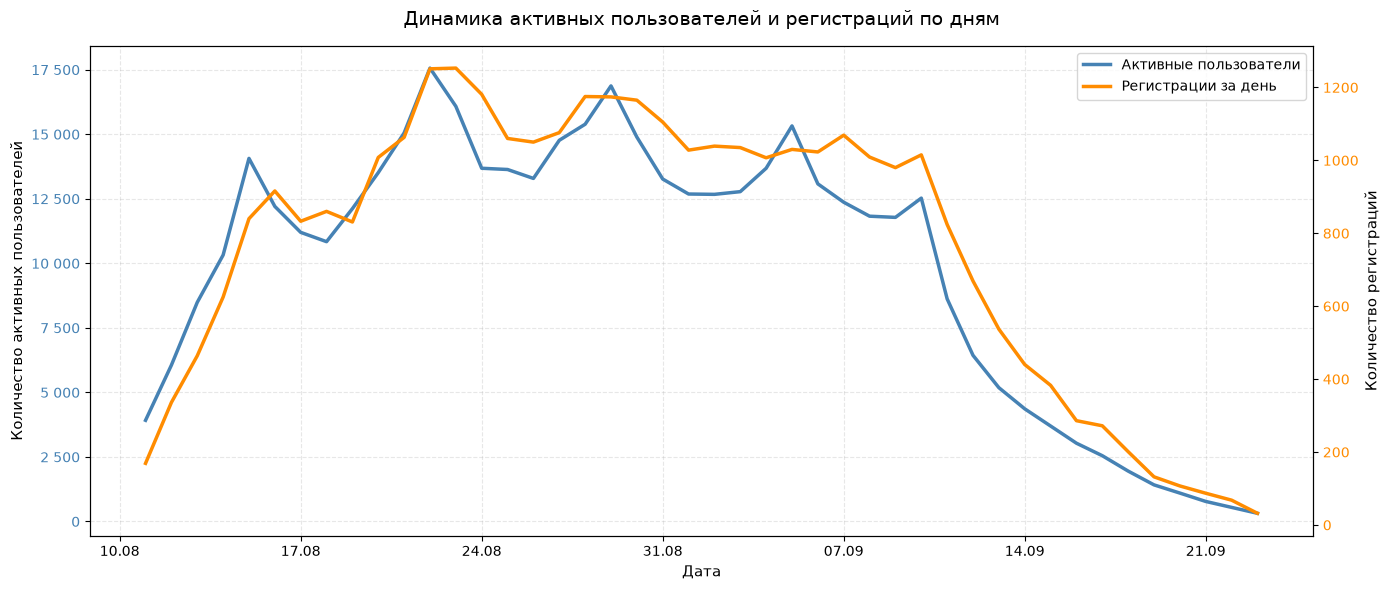

In [5]:
daily_stats.index = pd.to_datetime(daily_stats.index)
fig, ax1 = plt.subplots(figsize=(14, 6))

# ось Y — активные пользователи
line1 = ax1.plot(
    daily_stats.index,
    daily_stats['total_users'],
    color='steelblue',
    linewidth=2.5,
    label='Активные пользователи'
)

ax1.set_ylabel('Количество активных пользователей', fontsize=11)
ax1.set_xlabel('Дата', fontsize=11)

ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', ' '))
)

# ось Y — регистрации
ax2 = ax1.twinx()

line2 = ax2.plot(
    daily_stats.index,
    daily_stats['registered_users'],
    color='darkorange',
    linewidth=2.5,
    label='Регистрации за день'
)

ax2.set_ylabel('Количество регистраций', fontsize=11)
ax2.tick_params(axis='y', labelcolor='darkorange')


ax1.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))

plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
ax1.set_title(
    'Динамика активных пользователей и регистраций по дням',
    fontsize=14,
    pad=15
)
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.set_axisbelow(True)
lines = line1 + line2
labels = [line.get_label() for line in lines]

ax1.legend(lines, labels, loc='upper right', fontsize=10)
fig.tight_layout()

plt.show()

***В период с 11 августа по ~ 20 августа наблюдается рост числа активных пользователей и ежедневных регистраций. Но, с начала сентября начинается резкий спад активности и регистраций пользователей.***

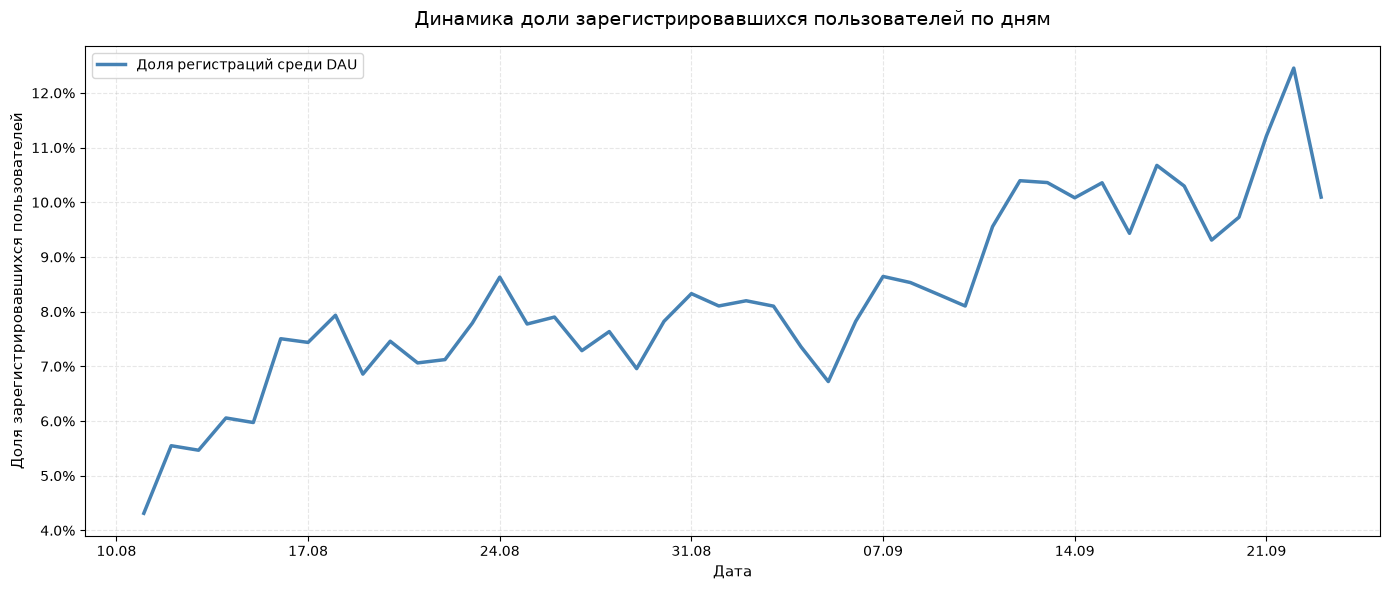

In [6]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    daily_stats.index,
    daily_stats['registration_share'],
    color='steelblue',
    linewidth=2.5,
    label='Доля регистраций среди DAU'
)

ax.set_xlabel('Дата', fontsize=11)
ax.set_ylabel('Доля зарегистрировавшихся пользователей', fontsize=11)
ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1, decimals=1)
)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))

plt.setp(ax.get_xticklabels(), rotation=0, ha='center')
ax.set_title(
    'Динамика доли зарегистрировавшихся пользователей по дням',
    fontsize=14,
    pad=15
)
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc='upper left', fontsize=10)
fig.tight_layout()

plt.show()

***По динамике доли зарегестрированных пользователей можно наблюдать противоположный эффект: она постепенно увеличивается с начала сентября. То есть, активность падает, а регистрации ростут.***

### **Общий вывод по динамике активности пользователей и числа регистраций:**
В августе доля и число зарегестрированных пользователей относительно ежедневной активности пользователей увеличивается. 
В начале сентября динамика данных показателей становится противоположной: число зарегестрированных пользователей в день сокращается, а доля продолжает увеличиваться.
Это может объясняться тем, что количество активных пользователей снижается быстрее, чем число регистраций. То есть, рост доли регистраций обусловлен прежде всего сокращением общего числа активных пользователей, а не увеличением количества регистраций.
Но, повышение вариативности доли в конце периода может быть связана с уменьшением числа наблюдений.


#### 1.4. Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

Проанализируем число просмотренных страниц во время первых сессий пользователей. Найдем количество первых сессий для каждого значения количества просмотренных страниц. 
Шаги:
- Построим столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий.

In [7]:
# Отбираем только первые сессии
first_sessions = sessions_history[
    sessions_history['session_number'] == 1
]

# Считаем количество первых сессий для каждого количества просмотренных страниц
pages_count = (
    first_sessions['page_counter']
    .value_counts()
    .sort_index()
)

print(pages_count)

page_counter
1     8978
2    32494
3    50939
4    32739
5     8075
6      777
7       37
Name: count, dtype: int64


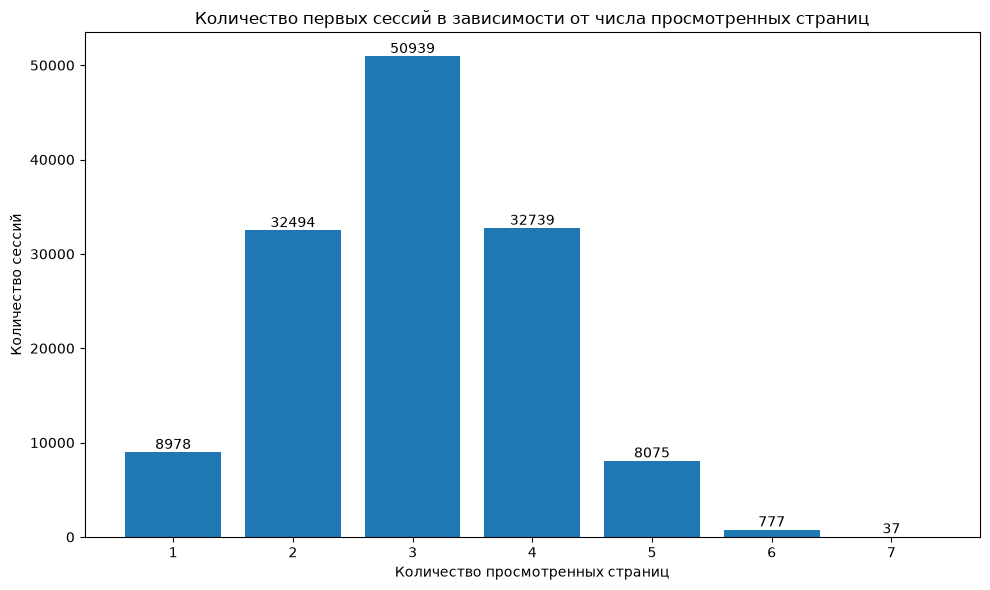

In [8]:
plt.figure(figsize=(10, 6))

bars = plt.bar(pages_count.index, pages_count.values)
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{int(height)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Количество первых сессий в зависимости от числа просмотренных страниц')
plt.xlabel('Количество просмотренных страниц')
plt.ylabel('Количество сессий')
plt.xticks(pages_count.index)
plt.tight_layout()
plt.show()

***Распределение числа просмотренных страниц в первых сессиях имеет выраженный пик на уровне трех страниц(50939). Большинство пользователей просматривают от 2 до 4 страниц, тогда как 5 и более страниц просматривает меньшее число пользователей. 
Это означает, что большее число пользователей не просматривают все стараницы, а завершают свое исследование на 3 страницах, что следует учитывать для дальнейшего анализа пользовательской активности и выборе метрики успешности первой сессии.***

#### 1.5. Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что первые сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.
Шаги:
- В датафрейме `sessions_history` создадим дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.

- Построим график со средним значением доли успешных первых сессий от всех первых сессий пользователей. Данные нужно визуализировать по дням за весь период наблюдения.

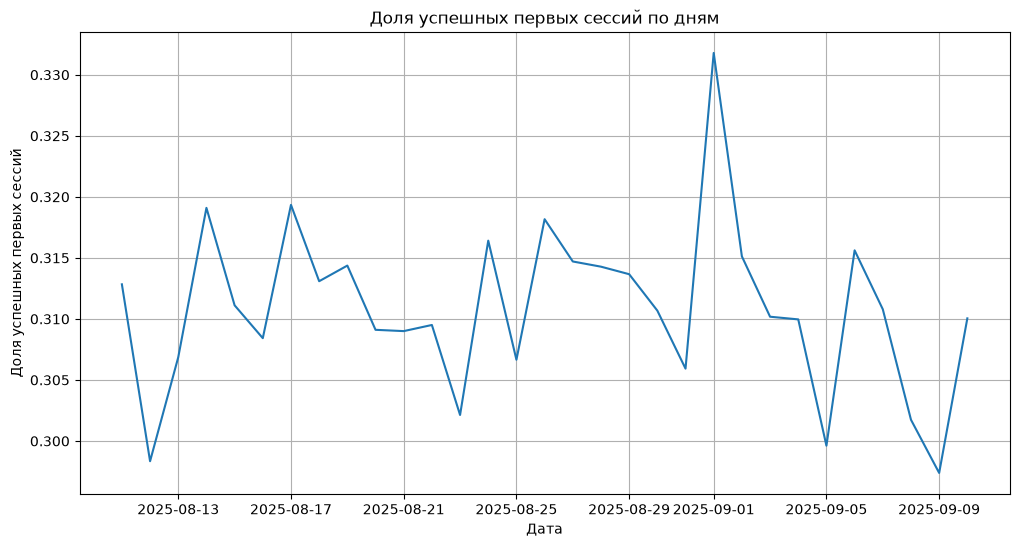

In [9]:
sessions_history['good_session'] = (
    sessions_history['page_counter'] >= 4
).astype(int)
first_sessions = sessions_history[
    sessions_history['session_number'] == 1
]
daily_good_sessions = (
    first_sessions
    .groupby('session_date')['good_session']
    .mean()
)
plt.figure(figsize=(12, 6))

plt.plot(
    daily_good_sessions.index,
    daily_good_sessions.values
)

plt.title('Доля успешных первых сессий по дням')
plt.xlabel('Дата')
plt.ylabel('Доля успешных первых сессий')

plt.grid(True)

plt.show()

***По представленной динамике доли успешных первых сессий можно сделать вывод, что показатель остается относительно стабильным в рамках первой сессии, колебание в рассматриваемом периоде преимущественно попадает в диапазон от 30 - 32%, пик которого приходится на первое сентября.*** 


### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1. Расчёт размера выборки
Рассчитаем необходимое для эксперимента количество пользователей.

Для этого установим в коде следующие параметры:

- Уровень значимости — 0.05.

- Вероятность ошибки второго рода — 0.2.

- Мощность теста - 0.8.

- Минимальный детектируемый эффект(MDE) — 3%. 

In [10]:
# Задаем параметры:
alpha = 0.05   # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.03 * p # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)
print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


#### 2.2. Расчёт длительности A/B-теста

Используем данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения. Рассчитаем длительность теста, разделив одно на другое.
Шаги:
- Рассчитаем среднее количество уникальных пользователей приложения в день.

- Определим длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. 

In [11]:
# Среднее количество пользователей приложения в день
avg_daily_users = (sessions_history.groupby('session_date')['user_id'].nunique().mean())
total = 2 * sample_size
# Длительность теста в днях 
test_duration = ceil(total/avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {avg_daily_users} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907.363636363636 пользователей в день составит 9 дней


### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие метрики корректно считаются.
Шаги:
- Сохраним в датафрейм `sessions_test_part` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test_part.csv`.

- Рассчитаем количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

- Рассчитаем и выведем на экран процентную разницу в количестве пользователей в группах A и B.

- ВИзуализируем на столбчатом графике возможное различие двух групп.

Для расчёта процентной разницы воспользуемся формулой:
$$P = 100 \cdot  \frac{|A − B|}{A}$$

In [12]:
sessions_test_part = pd.read_csv('sessions_project_test_part.csv')
users_by_group = (sessions_test_part.groupby('test_group')['user_id'].nunique())
A = users_by_group['A']
B = users_by_group['B']
percent_difference = 100*abs(A-B)/A
print(f'Процентная разница между группами: {percent_difference:.2f}%')

Процентная разница между группами: 0.74%


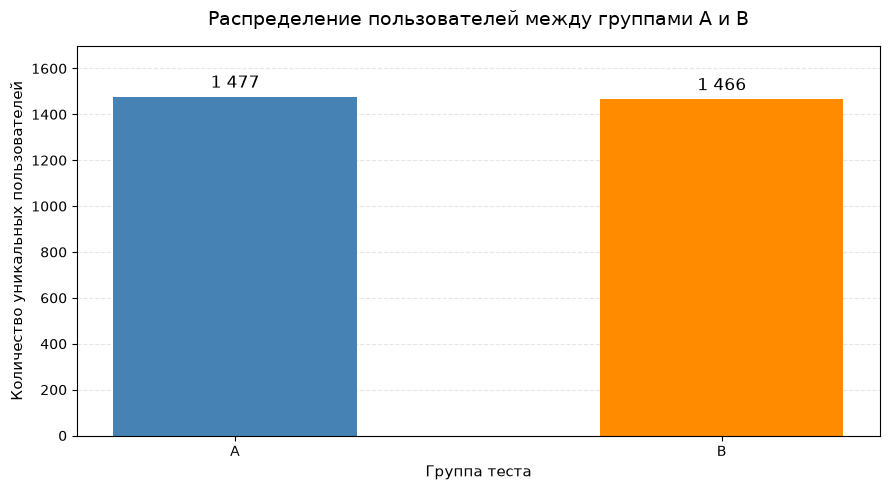

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    ['A', 'B'],
    [A, B],
    color=['steelblue', 'darkorange'],
    width=0.5
)
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + max(A, B) * 0.015,
        f'{int(height):,}'.replace(',', ' '),
        ha='center',
        va='bottom',
        fontsize=12
    )
ax.set_title(
    'Распределение пользователей между группами A и B',
    fontsize=14,
    pad=15
)

ax.set_xlabel('Группа теста', fontsize=11)
ax.set_ylabel('Количество уникальных пользователей', fontsize=11)

ax.set_ylim(0, max(A, B) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

***Проведено сравнение количества уникальных пользователей в контрольной (A) и экспериментальной (B) группах. Процентная разница между размерами групп составляет  0.74%. Столбчатая диаграмма позволяет наглядно оценить равномерность распределения участников. При небольшой разнице размеры групп можно считать близкими, что соответствует предполагаемому распределению пользователей 50/50. Однако для статистической проверки соответствия этому соотношению необходим дополнительный тест.***

#### 3.2. Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно проверить, что никто из пользователей случайно не попал в обе группы одновременно.
Шаги:
- Рассчитаем количество пользователей, которые встречаются одновременно в группах A и B, или убедимся, что таких нет.

In [14]:
user_a = set(sessions_test_part.loc[sessions_test_part['test_group']=='A', 'user_id'])
user_b = set(sessions_test_part.loc[sessions_test_part['test_group']=='B', 'user_id'])
intersection = user_a & user_b
print('Количество пересекающихся пользователей:', len(intersection))

Количество пересекающихся пользователей: 0


***Пересечений в группах не обнаружено, значит наши выборки независимы.***

#### 3.3. Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

Построим две диаграммы:

- доля каждого типа устройства для пользователей из группы A,

- доля каждого типа устройства для пользователей из группы B.

In [15]:
# 1. Количество уникальных пользователей по устройствам
device_users = (
    sessions_test_part
    .groupby(['test_group', 'device'])['user_id']
    .nunique()
    .unstack(fill_value=0)
    .reindex(['A', 'B'])
)

# Общее число уникальных пользователей в каждой группе
total_users = (
    sessions_test_part
    .groupby('test_group')['user_id']
    .nunique()
    .reindex(['A', 'B'])
)

# Доли уникальных пользователей по устройствам
device_share = device_users.div(total_users, axis=0)

device_table = pd.DataFrame({
    'Устройство': device_users.columns,
    'Пользователи A': device_users.loc['A'].values,
    'Доля A': device_share.loc['A'].values,
    'Пользователи B': device_users.loc['B'].values,
    'Доля B': device_share.loc['B'].values
})

device_table = (
    device_table
    .sort_values(by='Доля A', ascending=False)
    .reset_index(drop=True)
)

print('Распределение уникальных пользователей по устройствам:')

display(
    device_table.style.format({
        'Пользователи A': '{:,.0f}',
        'Доля A': '{:.1%}',
        'Пользователи B': '{:,.0f}',
        'Доля B': '{:.1%}'
    })
)

Распределение уникальных пользователей по устройствам:


,Устройство,Пользователи A,Доля A,Пользователи B,Доля B
0,Android,656,44.4%,668,45.6%
1,PC,369,25.0%,381,26.0%
2,iPhone,296,20.0%,269,18.3%
3,Mac,156,10.6%,148,10.1%


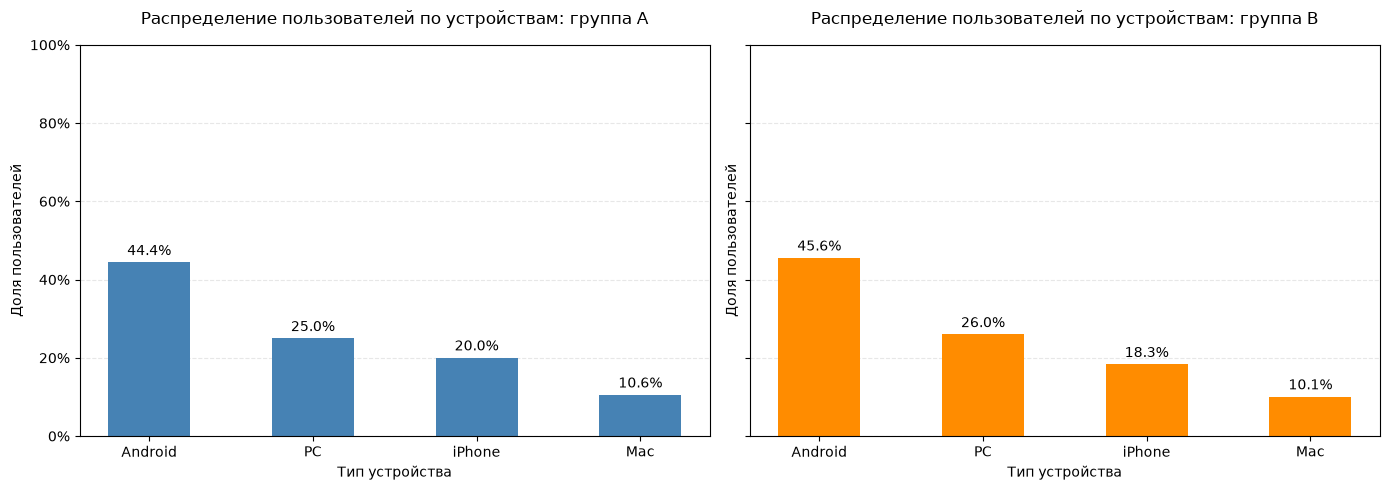

In [16]:
device_order = device_table['Устройство'].tolist()
device_share_sorted = device_share[device_order]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, group, color in zip(
    axes,
    ['A', 'B'],
    ['steelblue', 'darkorange']
):
    data = device_share_sorted.loc[group]

    bars = ax.bar(
        data.index,
        data.values,
        color=color,
        width=0.5
    )

    ax.set_title(
        f'Распределение пользователей по устройствам: группа {group}',
        fontsize=12,
        pad=15
    )

    ax.set_xlabel('Тип устройства')
    ax.set_ylabel('Доля пользователей')
    ax.set_ylim(0, 1)

    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)


    for bar, value in zip(bars, data.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.01,
            f'{value:.1%}',
            ha='center',
            va='bottom',
            fontsize=10
        )

plt.tight_layout()
plt.show()


**Вывод:** 
***Распределение пользователей по типам устройств в группах A и B практически совпадает. Наибольшую долю составляют пользователи Android (44,4% и 45,6% соответственно), далее следуют PC (25,0% и 26,0%), iPhone (20,0% и 18,3%) и Mac (10,6% и 10,1%). Максимальное различие наблюдается среди пользователей iPhone и составляет 1,7 процентного пункта.
Таким образом, группы сопоставимы по типам используемых устройств, выраженного дисбаланса не наблюдается, что свидетельствует в пользу корректного распределения участников A/B-теста.***

#### 3.4. Равномерность распределения пользователей по регионам
Теперь убедимся, что пользователи равномерно распределены по регионам.

Построим две диаграммы:

- доля каждого региона для пользователей из группы A,

- доля каждого региона для пользователей из группы B.

In [17]:
# 1. Количество уникальных пользователей по регионам
region_users = (
    sessions_test_part
    .groupby(['test_group', 'region'])['user_id']
    .nunique()
    .unstack(fill_value=0)
    .reindex(['A', 'B'])
)

# Общее количество уникальных пользователей в каждой группе
total_users = (
    sessions_test_part
    .groupby('test_group')['user_id']
    .nunique()
    .reindex(['A', 'B'])
)

# Доли уникальных пользователей по регионам
region_share = region_users.div(total_users, axis=0)
region_table = pd.DataFrame({
    'Регион': region_users.columns,
    'Пользователи A': region_users.loc['A'].values,
    'Доля A': region_share.loc['A'].values,
    'Пользователи B': region_users.loc['B'].values,
    'Доля B': region_share.loc['B'].values
})
region_table = (
    region_table
    .sort_values(by='Доля A', ascending=False)
    .reset_index(drop=True)
)

print('Распределение уникальных пользователей по регионам:')

display(
    region_table.style.format({
        'Пользователи A': '{:,.0f}',
        'Доля A': '{:.1%}',
        'Пользователи B': '{:,.0f}',
        'Доля B': '{:.1%}'
    })
)

Распределение уникальных пользователей по регионам:


,Регион,Пользователи A,Доля A,Пользователи B,Доля B
0,CIS,644,43.6%,645,44.0%
1,MENA,609,41.2%,604,41.2%
2,EU,224,15.2%,217,14.8%


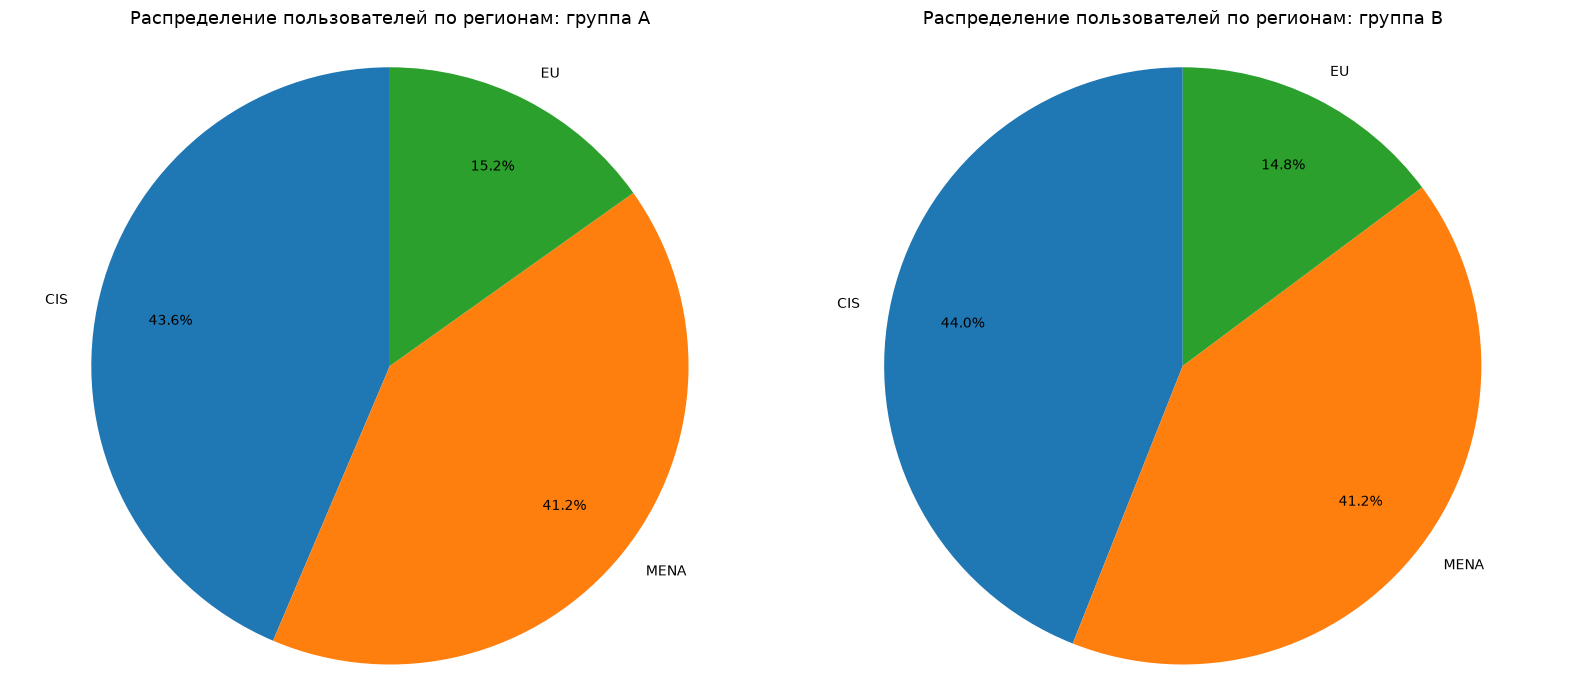

In [18]:
region_order = region_table['Регион'].tolist()
region_share_sorted = region_share[region_order]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, group in zip(axes, ['A', 'B']):

    data = region_share_sorted.loc[group]

    ax.pie(
        data.values,
        labels=data.index,
        autopct='%1.1f%%',
        startangle=90,
        pctdistance=0.75,
        textprops={'fontsize': 10}
    )

    ax.set_title(
        f'Распределение пользователей по регионам: группа {group}',
        fontsize=13,
        pad=20
    )

    ax.axis('equal')

plt.tight_layout()
plt.show()

**Вывод:** 

***Распределение пользователей по регионам в группах A и B практически идентично. Наибольшая доля приходится на регион CIS (43,6% и 44,0% соответственно), далее следуют MENA (41,2% в обеих группах) и EU (15,2% и 14,8%). Максимальное различие составляет всего 0,4 процентного пункта.***

**Таким образом, группы хорошо сбалансированы по региональному составу, существенных различий на описательном уровне не наблюдается, что также свидетельствует в пользу корректного распределения пользователей между группами.**

### Итоговый вывод по результатам мониторинга A/B-теста

На основе проведённого анализа сделаем краткое резюме:

- **Размеры групп:** разница в количестве уникальных пользователей между группами A и B составляет 0,74%, что указывает на достаточно равномерное распределение участников.
- **Независимость выборок:** пересечений пользователей между группами A и B не обнаружено. Следовательно, каждый пользователь участвует только в одной экспериментальной группе.
- **Распределение по устройствам:** доли уникальных пользователей по типам устройств в группах A и B близки. Например, доля пользователей Android составляет 43,7% и 44,4% соответственно. Небольшие различия не указывают на выраженный дисбаланс между группами.
- **Распределение по регионам:** группы практически идентичны по региональному составу. В группе A доля CIS составляет 43,6%, MENA — 41,2%, EU — 15,2%; в группе B — 44,0%, 41,2% и 14,8% соответственно. Максимальное различие составляет всего 0,4 процентного пункта.

**Заключение:** По результатам мониторинга группы A и B сопоставимы по численности, типам устройств и региональному составу. Пересечений пользователей между группами не обнаружено. Таким образом, признаков существенных нарушений распределения участников не выявлено, и исследование можно продолжать. 

### 4. Проверка результатов A/B-теста

A/B-тест завершён, и у нас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

- Сохраним в датафрейм `sessions_test` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.

- В датафрейме `sessions_test` создадим дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [19]:
sessions_test = pd.read_csv('sessions_project_test.csv')
sessions_test['good_sessions'] = (sessions_test['page_counter']>=4).astype(int)
sessions_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_sessions
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик


Перед тем как проводить А/B-тест, сформулируем нулевую и альтернативную гипотезы. Повторим изначальное условие: команда разработчиков рекомендательных систем создала новый алгоритм, который, по их мнению, будет показывать более интересный контент для каждого пользователя.

На основе требований сформулируем целевую метрику, а также нулевую и альтернативную гипотезы.

1) **Целевая метрика**

Так как команда предполагает, что новая рекомендательна система будет способствовать удержанию пользователей на сайте, влияя на количество просмотренных страниц, то целевой метрикой будет - **"доля успешных первых сессий"** (то есть те, где пользователь посмотрел 4 и более страниц).

2) **Нулевая и альтернативная гипотезы**

**Н0:** Внедрение нового алгоритма рекомендаций не увеличит долю пользователей, просмотревших 4 и более страниц в первой сессии. То есть, доля успешных сессий в контрольной группе  (A) равна доле успешных сессий в  экспериментальной группе (B): H0:pA=pB

**Н1:** Внедрение нового алгоритма рекомендаций увеличит долю пользователей, просмотревших 4 и более страниц первой сессии. То есть доля успешных сессй в тестовой группе (B) будет выше, чем в контрольной группе (A): H1:pA<pB


#### 4.3. Сравнение доли успешных первых сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

Используем созданный столбец `good_session` и рассчитаем долю успешных первых сессий для выборок A и B, а также разницу в этом показателе.

In [20]:
# Отбираем только первые сессии пользователей
first_sessions_test = sessions_test[sessions_test['session_number'] == 1]

# Считаем долю успешных первых сессий в каждой группе
share_a = first_sessions_test[
    first_sessions_test['test_group'] == 'A'
]['good_sessions'].mean()

share_b = first_sessions_test[
    first_sessions_test['test_group'] == 'B'
]['good_sessions'].mean()

# Абсолютная и относительная разница
abs_diff = share_b - share_a
rel_diff = abs_diff / share_a * 100

print(f"Доля успешных первых сессий в группе A (контрольная группа): {share_a:.4f} ({share_a:.2%})")
print(f"Доля успешных первых сессий в группе B (экспериментальная группа):    {share_b:.4f} ({share_b:.2%})")
print(f"Абсолютная разница (B − A): {abs_diff:+.4f}")
print(f"Относительная разница (B − A) / A: {rel_diff:+.2f}%")

Доля успешных первых сессий в группе A (контрольная группа): 0.3157 (31.57%)
Доля успешных первых сессий в группе B (экспериментальная группа):    0.3147 (31.47%)
Абсолютная разница (B − A): -0.0011
Относительная разница (B − A) / A: -0.33%


#### 4.4. Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге мы убедились, что доли успешных первых сессий в тестовой и контрольной выборках близки, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

- Используя статистический тест, рассчитаем, является ли изменение в метрике доли успешных первых сессий статистически значимым. Для этого воспользуемя односторонним z-тестом для сравнения долей.

In [21]:
# Количество успешных первых сессий в каждой группе
successes = [
    first_sessions_test[
        first_sessions_test['test_group'] == 'B'
    ]['good_sessions'].sum(),

    first_sessions_test[
        first_sessions_test['test_group'] == 'A'
    ]['good_sessions'].sum()
]

# Общее количество первых сессий в каждой группе
totals = [
    first_sessions_test[
        first_sessions_test['test_group'] == 'B'
    ]['good_sessions'].count(),

    first_sessions_test[
        first_sessions_test['test_group'] == 'A'
    ]['good_sessions'].count()
]

print("Успешных первых сессий (B, A):", successes)
print("Всего первых сессий (B, A):", totals)

# Рассчитываем долю успешных сессий
p_B = successes[0] / totals[0]
p_A = successes[1] / totals[1]

print(f"Доля успешных сессий в группе B: {p_B:.2%}")
print(f"Доля успешных сессий в группе A: {p_A:.2%}")
print(f"Разница между группами: {(p_B - p_A) * 100:.2f} п. п.")

z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=totals,
    alternative='larger'
)

alpha = 0.05

print(f"\nz-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < alpha:
    print(
        f"p-value = {p_value:.4f} < {alpha} — отвергаем H₀. "
        "Доля успешных первых сессий в группе B "
        "статистически значимо выше, чем в группе A."
    )
else:
    print(
        f"p-value = {p_value:.4f} ≥ {alpha} — "
        "нет оснований отвергнуть H₀. "
        "Статистически значимое улучшение "
        "в группе B не обнаружено."
    )

Успешных первых сессий (B, A): [np.int64(4851), np.int64(4787)]
Всего первых сессий (B, A): [np.int64(15416), np.int64(15162)]
Доля успешных сессий в группе B: 31.47%
Доля успешных сессий в группе A: 31.57%
Разница между группами: -0.11 п. п.

z-статистика: -0.1977
p-value: 0.5784
p-value = 0.5784 ≥ 0.05 — нет оснований отвергнуть H₀. Статистически значимое улучшение в группе B не обнаружено.


**Вывод:**

Доля успешных первых сессий в экспериментальной группе B составила 31,47%, что на 0,11 процентного пункта ниже, чем в контрольной группе A (31,57%). По результатам одностороннего z-теста различие не подтверждает гипотезу об улучшении метрики (p-value = 0,5784 > 0,05). 
Таким образом,статистически значимого положительного эффекта нового алгоритма рекомендаций не обнаружено.

#### 4.5. Вывод по результатам A/B-эксперимента

На основе проведённого анализа результатов теста сформулируем выводы для команды разработки приложения.

***1. Характеристики эксперимента***

A/B-тест проводился с 14 октября по 2 ноября 2025 года (20 дней). В эксперименте участвовали 30 578 пользователей: 15 162 в контрольной группе A и 15 416 в экспериментальной группе B.

Ключевая метрика — доля успешных первых сессий (просмотр 4 и более страниц). В группе A она составила 31,57%, в группе B — 31,47%. Таким образом, метрика снизилась примерно на 0,10 процентного пункта.

***2. Результаты проверки гипотез***

Для проверки гипотезы об увеличении доли успешных первых сессий в группе B проведён односторонний z-тест. Полученное p-value = 0,5784 > 0,05, поэтому оснований отвергнуть нулевую гипотезу нет. Статистически значимое улучшение не обнаружено.

***3. Итоговый вывод***

Новый алгоритм рекомендаций не продемонстрировал статистически значимого положительного влияния на ключевую метрику. Внедрение алгоритма по результатам данного A/B-теста не рекомендуется, поскольку его преимущество перед текущим решением не подтверждено.